In [1]:
import os
import pymc as pm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pytensor.tensor as pt

In [2]:
os.getcwd()

'/home/claude/ts'

In [3]:
# CSV из свежей версии yfinance: под шапкой две служебные строки (тикер и "Date"),
# а даты идут от новых к старым, поэтому пропускаем эти строки и сортируем по дате
data = (
    pd.read_csv("aapl.csv", skiprows=[1, 2], index_col=0, parse_dates=True)
    .rename_axis("Date")
    .sort_index()
)
data.head()

,Close,High,Low,Open,Volume
Date,,,,,
2020-12-07,120.882,121.669,119.413,119.472,88677046
2020-12-08,121.483,122.074,120.232,121.473,83958145
2020-12-09,118.949,123.030,118.191,121.630,117607137
2020-12-10,120.378,121.000,117.373,117.707,83244691
2020-12-11,119.571,119.906,117.757,119.590,89006419


In [ ]:
data.dtypes

Close     float64
High      float64
Low       float64
Open      float64
Volume      int64
dtype: object

In [ ]:
# в новых выгрузках yfinance нет колонки Adj Close: Close уже скорректирована на дивиденды и сплиты
close_price = data["Close"]

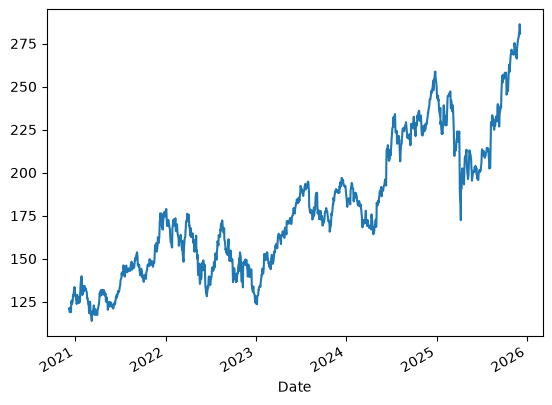

In [ ]:
close_price.plot();

In [ ]:
change_pct = close_price.pct_change()[1:]

<Axes: xlabel='Date'>

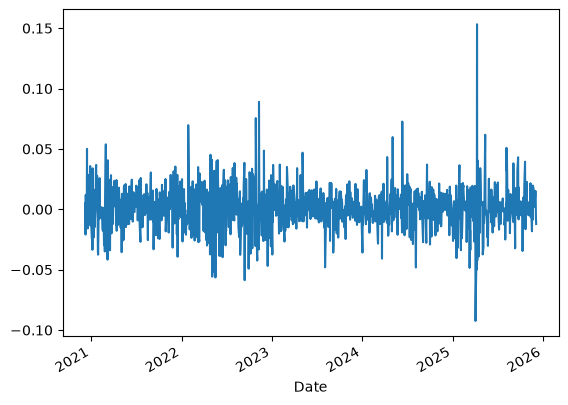

In [ ]:
change_pct.plot()

In [ ]:
mean_std = (1+1) ** (1/250) - 1

In [ ]:
obs_log_std = np.log(mean_std)

In [ ]:
with pm.Model(coords=dict(time=change_pct.index)) as model_simple:
    mean_return = pm.Normal("mean_std", 0, mean_std)
    day_log_volatility = pm.Normal("day_log_std", obs_log_std, 0.1)
    pm.Normal("returns", mean_return, pt.exp(day_log_volatility), observed=change_pct, dims="time")

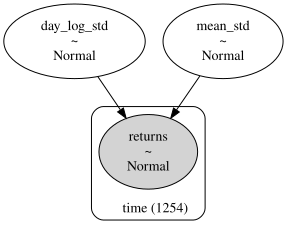

In [ ]:
pm.model_to_graphviz(model_simple)

In [ ]:
with model_simple:
    # вместо numpyro (нужен jax) используем штатный pm.sample — он сам выберет nutpie, если тот установлен
    trace = pm.sample()

NUTS[nutpie]: [mean_std, day_log_std]


In [ ]:
import arviz as az

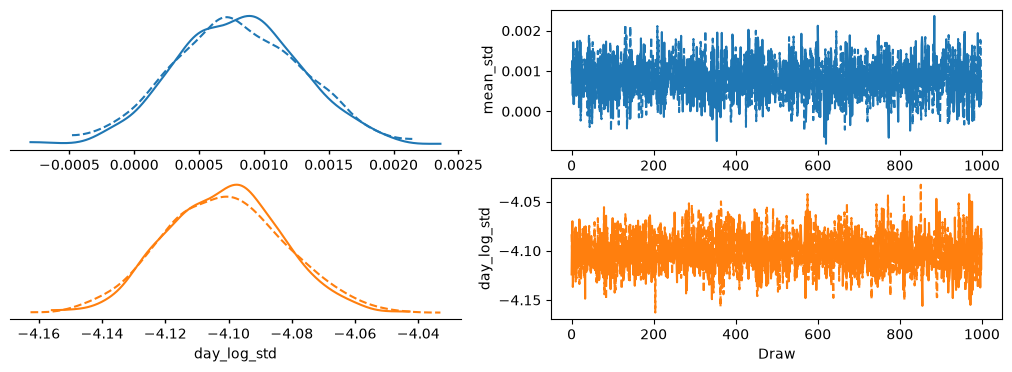

In [ ]:
# в ArviZ 1.x plot_trace рисует только трейсы, плотности вместе с трассами — plot_trace_dist
az.plot_trace_dist(trace)

In [ ]:
((trace.posterior["mean_std"]+1)**250-1).mean()

<xarray.DataArray 'mean_std' ()> Size: 8B
array(0.22956015)

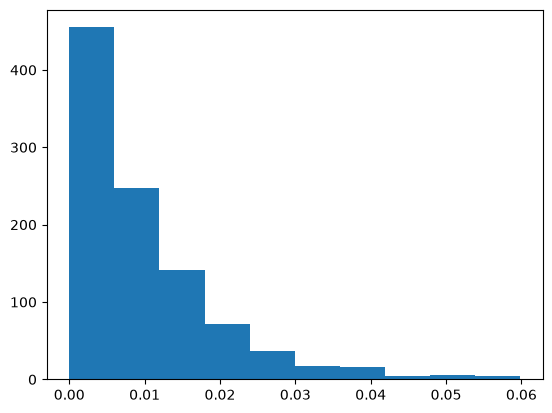

In [ ]:
alpha_dstd_prior = pm.Exponential.dist(100)
plt.hist(pm.draw(alpha_dstd_prior, 1000));

In [ ]:
time_baseline = pd.to_datetime("2024-1-1")
time_baseline

Timestamp('2024-01-01 00:00:00')

In [ ]:
change_pct.index.mean()

Timestamp('2023-06-06 21:22:40.765550336')

In [ ]:
days_time = change_pct.index - change_pct.index.mean()
# полуширина временного диапазона в днях — от неё зависят параметры HSGP
half_range = np.abs(days_time.days).max()
min(days_time.days), max(days_time.days)

(-911, 911)

In [ ]:
half_range * .2

np.float64(182.20000000000002)

In [ ]:
required_m = int(3.42 * (half_range * 1.2) / 5)
required_m 

747

In [ ]:
with pm.Model(coords=dict(time=change_pct.index)) as model:
    days_time = pm.Data("numeric_time", (change_pct.index - change_pct.index.mean()).days, dims="time")

    mean_return = pm.Normal("mean_std", 0, mean_std)
    day_log_volatility = pm.Normal("day_log_std", obs_log_std, 0.1)
    
    alpha_dstd = pm.Exponential("alpha_dstd", 100)
    ls = pm.Gamma("ls_days", mu=30, sigma=5)
    
    kernel = pm.gp.cov.Matern32(1, ls=ls) * alpha_dstd
    
    gp = pm.gp.HSGP([required_m], [half_range * 1.2], drop_first=True, cov_func=kernel)
    delta_volatility = gp.prior("delta_volatility", days_time[:, None], dims="time")
    day_std = pm.Deterministic("day_std", pt.exp(day_log_volatility + delta_volatility), dims="time")
    pm.Normal("returns", mean_return, day_std, observed=change_pct, dims="time")

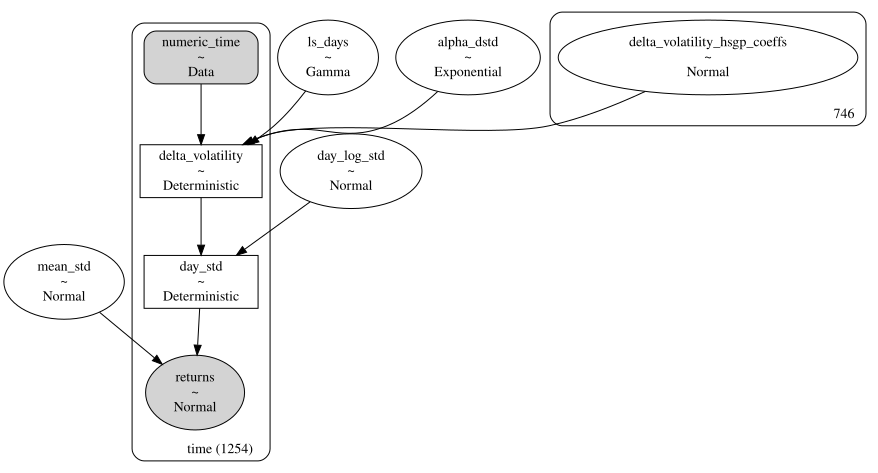

In [ ]:
pm.model_to_graphviz(model)

In [ ]:
with model:
    trace = pm.sample(chains=2)

NUTS[nutpie]: [mean_std, day_log_std, alpha_dstd, ls_days, delta_volatility_hsgp_coeffs]


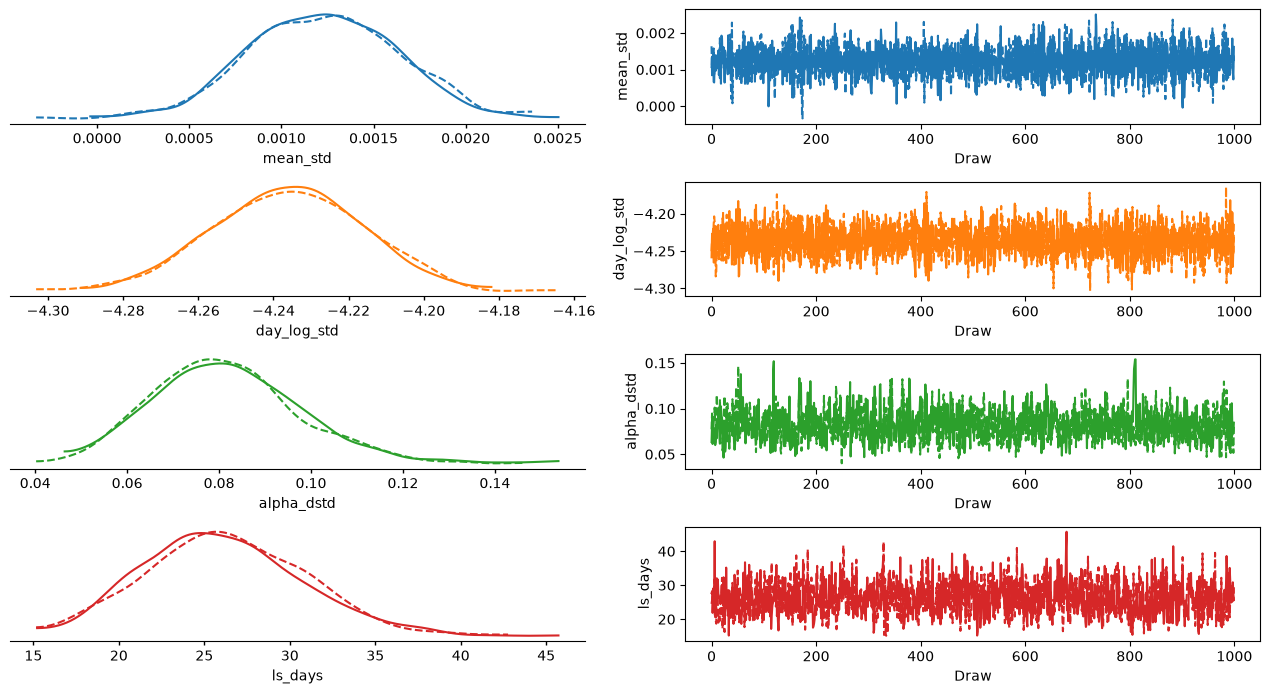

In [ ]:
az.plot_trace_dist(trace, var_names=["mean_std", "day_log_std", "alpha_dstd", "ls_days"]);
plt.tight_layout()

In [ ]:
((trace.posterior["mean_std"]+1)**250-1).mean()

<xarray.DataArray 'mean_std' ()> Size: 8B
array(0.36563598)

In [ ]:
az.extract(trace.posterior)["day_std"].values

array([[0.01938783, 0.01789862, 0.01641612, ..., 0.01897874, 0.01301528,
        0.02439269],
       [0.01922451, 0.01810642, 0.01633699, ..., 0.01904937, 0.01319812,
        0.02417063],
       [0.01895504, 0.01832228, 0.01630733, ..., 0.01910027, 0.01337059,
        0.02399683],
       ...,
       [0.00827389, 0.01015359, 0.01119982, ..., 0.01323886, 0.01047353,
        0.01080435],
       [0.00821031, 0.00993292, 0.01164527, ..., 0.01322901, 0.01065744,
        0.01078851],
       [0.00814309, 0.00975098, 0.0121005 , ..., 0.01325318, 0.01085597,
        0.01078855]], shape=(1254, 2000))

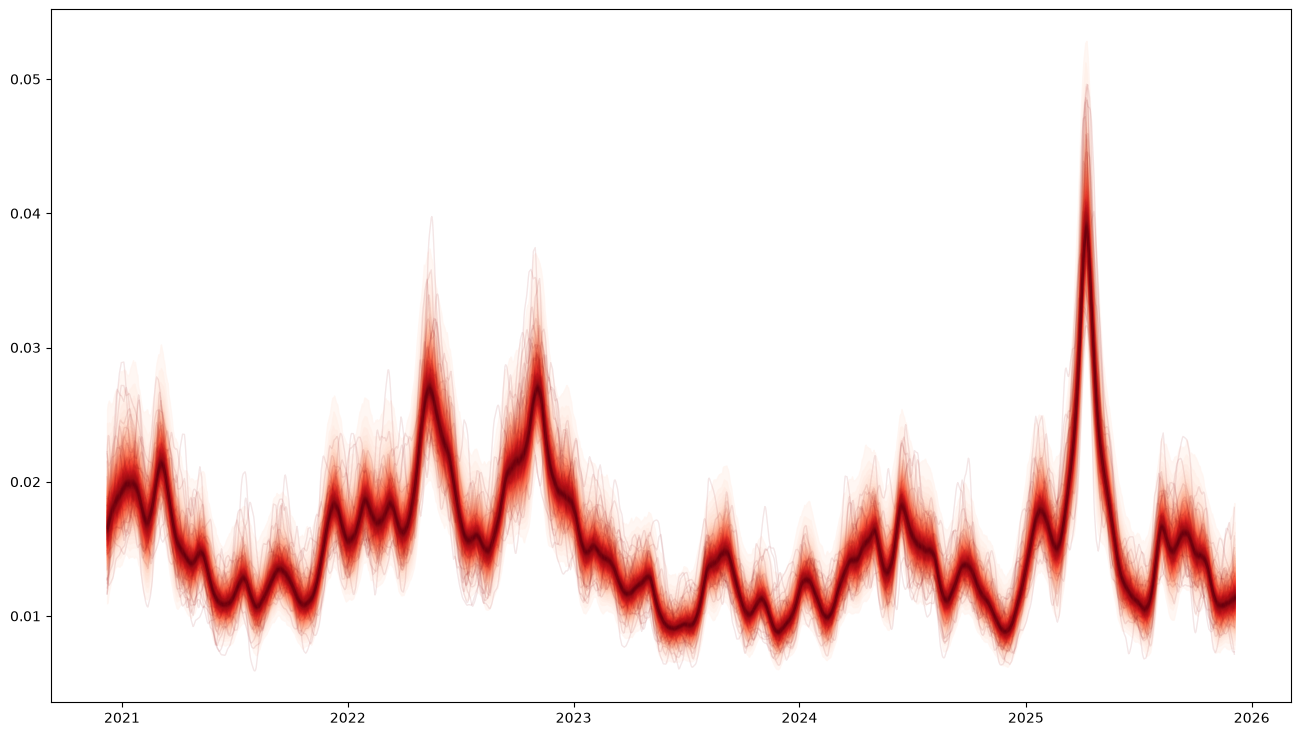

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(16, 9))
pm.gp.util.plot_gp_dist(ax, az.extract(trace.posterior)["day_std"].values.T, x=change_pct.index.values);